1. Import, clean and inspect data
Purpose: Load the dataset, check its structure, identify missing values and duplicates, and prepare it for analysis.

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from IPython.display import display

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


Code cell 1.2 — Upload and read the CSV dataset

In [2]:

from google.colab import files
import io

uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a valid CSV dataset.")

filename = "mentor_dataset.csv" if "mentor_dataset.csv" in csv_files else csv_files[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Saving mentor_dataset.csv to mentor_dataset.csv
Dataset loaded successfully!
Dataset shape: (30, 1)


,"mentor_id,name,skills,career_goal,level,industry,years_experience,rating,completed_sessions,availability"
0,"M001,Ananya Rao,Python; SQL; Machine Learning;..."
1,"M002,Rahul Menon,Java; Data Structures; Algori..."
2,"M003,Priya Nair,Python; Deep Learning; Neural ..."
3,"M004,Arjun Kumar,Cybersecurity; Networking; Li..."
4,"M005,Meera Iyer,Business Analysis; Communicati..."


Code cell 1.3 — Inspect the dataset

In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['mentor_id,name,skills,career_goal,level,industry,years_experience,rating,completed_sessions,availability']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 1 columns):
 #   Column                                                                                                    Non-Null Count  Dtype 
---  ------                                                                                                    --------------  ----- 
 0   mentor_id,name,skills,career_goal,level,industry,years_experience,rating,completed_sessions,availability  30 non-null     object
dtypes: object(1)
memory usage: 372.0+ bytes

First five rows:


,"mentor_id,name,skills,career_goal,level,industry,years_experience,rating,completed_sessions,availability"
0,"M001,Ananya Rao,Python; SQL; Machine Learning;..."
1,"M002,Rahul Menon,Java; Data Structures; Algori..."
2,"M003,Priya Nair,Python; Deep Learning; Neural ..."
3,"M004,Arjun Kumar,Cybersecurity; Networking; Li..."
4,"M005,Meera Iyer,Business Analysis; Communicati..."



Missing values:


,0
"mentor_id,name,skills,career_goal,level,industry,years_experience,rating,completed_sessions,availability",0



Duplicate rows: 0


Code cell 1.4 — Validate and clean data
This cell checks required columns, removes duplicate mentor IDs, fills missing numerical values, and standardizes text columns.

In [4]:
df = df.copy()

# If the CSV was parsed as a single column due to formatting issues, split it
if len(df.columns) == 1 and ',' in df.columns[0]:
    col_name = df.columns[0]
    headers = col_name.split(',')
    # Split the single text column into multiple columns
    temp_df = df[col_name].str.split(',', expand=True)
    if temp_df.shape[1] == len(headers):
        temp_df.columns = headers
        df = temp_df

# Map the CSV columns to match the required column names in the notebook
column_mapping = {
    "name": "mentor_name",
    "skills": "expertise_skills",
    "career_goal": "primary_career_goal",
    "years_experience": "experience_years",
    "rating": "session_rating",
    "level": "mentee_level_supported",
    "availability": "available_slots"
}

df = df.rename(columns=column_mapping)

# Add any missing required column with default/median values
if "hourly_rate_inr" not in df.columns:
    df["hourly_rate_inr"] = 0

required_columns = [
    "mentor_id",
    "mentor_name",
    "primary_career_goal",
    "expertise_skills",
    "industry",
    "experience_years",
    "mentee_level_supported",
    "session_rating",
    "completed_sessions",
    "available_slots",
    "hourly_rate_inr"
]

missing_columns = set(required_columns) - set(df.columns)
if missing_columns:
    raise ValueError(
        f"Dataset is missing these columns: {sorted(missing_columns)}"
    )

text_columns = [
    "mentor_id",
    "mentor_name",
    "primary_career_goal",
    "expertise_skills",
    "industry",
    "mentee_level_supported",
    "available_slots"
]

for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

numeric_columns = [
    "experience_years",
    "session_rating",
    "completed_sessions",
    "hourly_rate_inr"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    median_value = df[col].median()
    df[col] = df[col].fillna(
        0 if pd.isna(median_value) else median_value
    )

df = df.drop_duplicates(subset=["mentor_id"], keep="first")

df["experience_years"] = df["experience_years"].clip(0, 60)
df["session_rating"] = df["session_rating"].clip(0, 5)
df["completed_sessions"] = df["completed_sessions"].clip(lower=0)
df["hourly_rate_inr"] = df["hourly_rate_inr"].clip(lower=0)

df = df[
    (df["mentor_id"] != "") &
    (df["primary_career_goal"].str.strip() != "") &
    (df["expertise_skills"].str.strip() != "")
].reset_index(drop=True)

if df.empty:
    raise ValueError("No usable mentor records remain after cleaning.")

print("Data cleaning completed.")
print("Cleaned dataset shape:", df.shape)
display(df.head())

Data cleaning completed.
Cleaned dataset shape: (30, 11)


,mentor_id,mentor_name,expertise_skills,primary_career_goal,mentee_level_supported,industry,experience_years,session_rating,completed_sessions,available_slots,hourly_rate_inr
0,M001,Ananya Rao,Python; SQL; Machine Learning; Data Analysis,Data Scientist,Beginner,Technology,3,4.7,42,Weekday evenings,0
1,M002,Rahul Menon,Java; Data Structures; Algorithms; Backend Dev...,Software Engineer,Beginner,Technology,5,4.8,65,Weekends,0
2,M003,Priya Nair,Python; Deep Learning; Neural Networks; NLP,AI Engineer,Intermediate,Technology,6,4.9,78,Weekday evenings,0
3,M004,Arjun Kumar,Cybersecurity; Networking; Linux; Ethical Hacking,Cybersecurity Analyst,Beginner,Cybersecurity,4,4.5,31,Weekends,0
4,M005,Meera Iyer,Business Analysis; Communication; Product Stra...,Product Manager,Intermediate,Consulting,7,4.6,54,Weekday afternoons,0


2. Exploratory data analysis and descriptive statistics
Purpose: Understand the distribution of mentor experience, ratings, industries, career goals, and pricing.

In [5]:

numeric_columns = [
    "experience_years",
    "session_rating",
    "completed_sessions",
    "hourly_rate_inr"
]

print("Descriptive statistics:")
display(df[numeric_columns].describe().T)

print("\nMean:")
display(df[numeric_columns].mean().to_frame("Mean"))

print("\nMedian:")
display(df[numeric_columns].median().to_frame("Median"))

print("\nVariance:")
display(df[numeric_columns].var().to_frame("Variance"))

print("\nStandard deviation:")
display(df[numeric_columns].std().to_frame("Standard Deviation"))


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
experience_years,30.0,6.066667,2.083322,2.0,5.0,6.00,7.75,10.0
session_rating,30.0,4.640000,0.177337,4.3,4.5,4.65,4.80,4.9
completed_sessions,30.0,57.333333,24.673500,21.0,39.5,53.00,73.50,112.0
hourly_rate_inr,30.0,0.000000,0.000000,0.0,0.0,0.00,0.00,0.0



Mean:


,Mean
experience_years,6.066667
session_rating,4.640000
completed_sessions,57.333333
hourly_rate_inr,0.000000



Median:


,Median
experience_years,6.00
session_rating,4.65
completed_sessions,53.00
hourly_rate_inr,0.00



Variance:


,Variance
experience_years,4.340230
session_rating,0.031448
completed_sessions,608.781609
hourly_rate_inr,0.000000



Standard deviation:


,Standard Deviation
experience_years,2.083322
session_rating,0.177337
completed_sessions,24.673500
hourly_rate_inr,0.000000


Code cell 2.2 — Mentor experience distribution

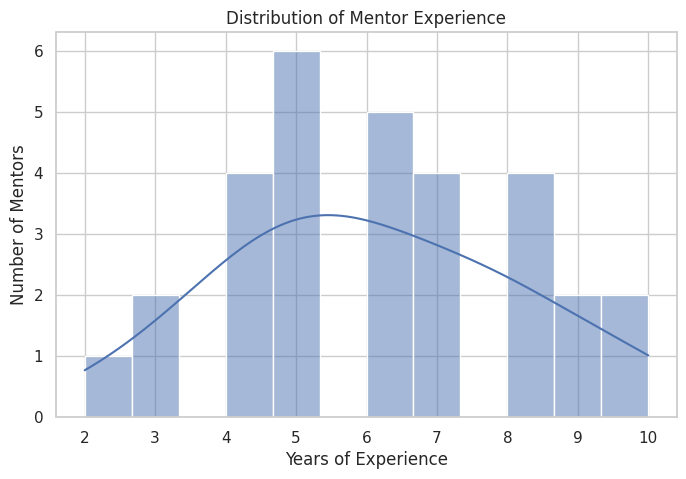

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="experience_years",
    bins=12,
    kde=True
)

plt.title("Distribution of Mentor Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Mentors")
plt.show()


Code cell 2.3 — Ratings distribution

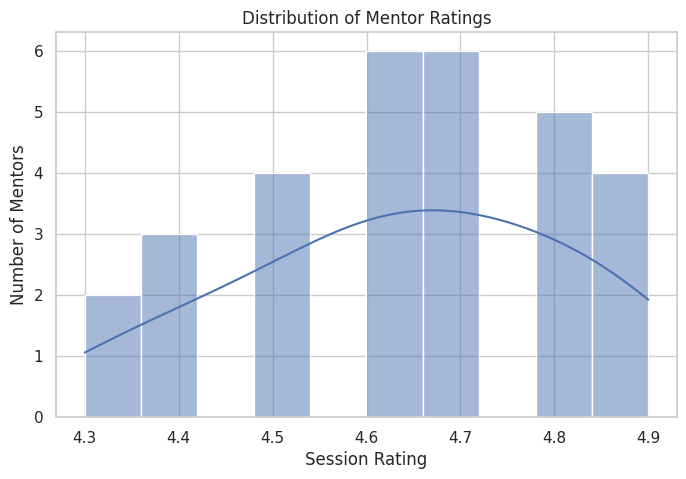

In [7]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="session_rating",
    bins=10,
    kde=True
)

plt.title("Distribution of Mentor Ratings")
plt.xlabel("Session Rating")
plt.ylabel("Number of Mentors")
plt.show()


Code cell 2.4 — Career goal analysis

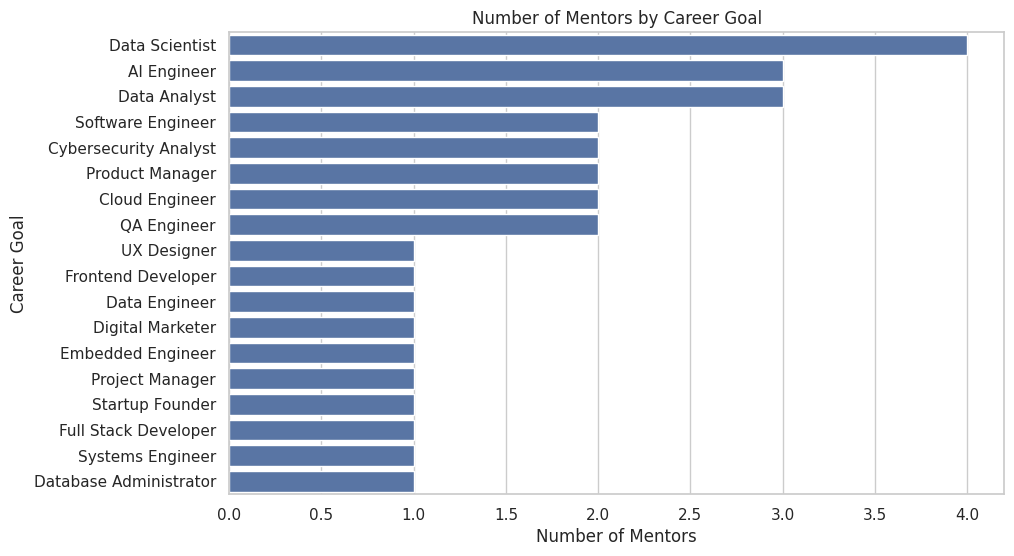

,Number of Mentors
primary_career_goal,
Data Scientist,4
AI Engineer,3
Data Analyst,3
Software Engineer,2
Cybersecurity Analyst,2
Product Manager,2
Cloud Engineer,2
QA Engineer,2
UX Designer,1


In [8]:

goal_counts = df["primary_career_goal"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=goal_counts.values,
    y=goal_counts.index
)

plt.title("Number of Mentors by Career Goal")
plt.xlabel("Number of Mentors")
plt.ylabel("Career Goal")
plt.show()

display(goal_counts.to_frame("Number of Mentors"))


Code cell 2.5 — Industry analysis

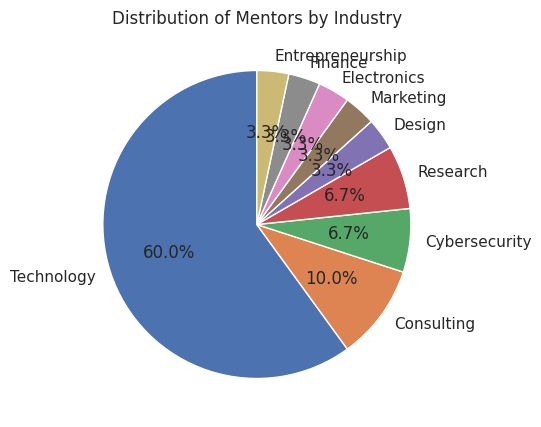

In [9]:

industry_counts = df["industry"].value_counts()

plt.figure(figsize=(9, 5))

plt.pie(
    industry_counts.values,
    labels=industry_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Mentors by Industry")
plt.show()


Code cell 2.6 — Correlation analysis

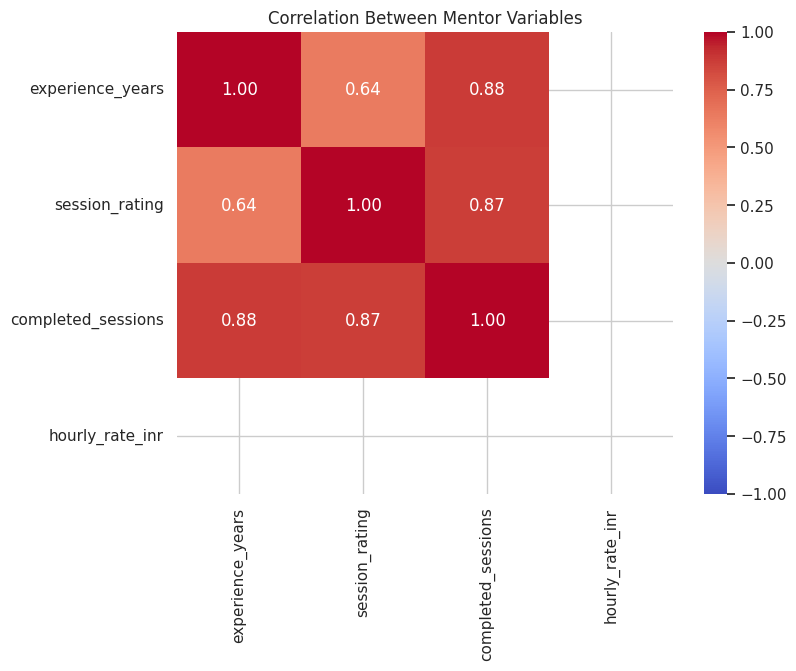

In [10]:

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Mentor Variables")
plt.show()


3. Models and evaluation design
Purpose: Recommend suitable mentors using content-based filtering and compare the approach with a simple popularity baseline.

The content-based model uses TF-IDF to represent mentor profiles as numerical vectors. Cosine similarity measures how closely each mentor's profile matches a candidate's career goal and skills.

In [11]:

df["profile_text"] = (
    df["primary_career_goal"] + " " +
    df["expertise_skills"].str.replace(";", " ", regex=False) + " " +
    df["industry"] + " " +
    df["mentee_level_supported"].str.replace(";", " ", regex=False)
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

mentor_matrix = vectorizer.fit_transform(df["profile_text"])

print("Mentor profile vectors created.")
print("Vector matrix shape:", mentor_matrix.shape)


Mentor profile vectors created.
Vector matrix shape: (30, 321)


Code cell 3.2 — Create the recommendation function

In [12]:

def recommend_mentors(
    career_goal,
    skills,
    level="Beginner",
    industry="",
    top_n=5
):
    if not str(career_goal).strip():
        raise ValueError("Enter a career goal.")

    if not str(skills).strip():
        raise ValueError("Enter at least one skill.")

    candidate_text = (
        str(career_goal) + " " +
        str(skills).replace(";", " ").replace(",", " ") + " " +
        str(industry) + " " +
        str(level)
    )

    candidate_vector = vectorizer.transform([candidate_text])

    similarities = cosine_similarity(
        candidate_vector,
        mentor_matrix
    ).flatten()

    results = df.copy()
    results["similarity_score"] = similarities

    results = results.sort_values(
        "similarity_score",
        ascending=False
    ).head(top_n)

    return results[
        [
            "mentor_id",
            "mentor_name",
            "primary_career_goal",
            "expertise_skills",
            "industry",
            "experience_years",
            "session_rating",
            "available_slots",
            "similarity_score"
        ]
    ]


Code cell 3.3 — Test the recommendation model

In [13]:

recommendations = recommend_mentors(
    career_goal="Data Scientist",
    skills="Python; Machine Learning; SQL",
    level="Beginner",
    industry="Technology",
    top_n=5
)

display(recommendations)


,mentor_id,mentor_name,primary_career_goal,expertise_skills,industry,experience_years,session_rating,available_slots,similarity_score
0,M001,Ananya Rao,Data Scientist,Python; SQL; Machine Learning; Data Analysis,Technology,3,4.7,Weekday evenings,0.713603
20,M021,Pooja Suresh,Data Scientist,Python; NLP; Text Mining; Machine Learning,Technology,8,4.9,Weekends,0.504209
8,M009,Divya Thomas,Data Scientist,Python; Statistics; Machine Learning; Research,Research,5,4.6,Weekday afternoons,0.502606
23,M024,Harish Patel,Data Scientist,Machine Learning; Statistics; Python; Data Vis...,Research,6,4.7,Weekends,0.439579
5,M006,Kiran Das,Data Analyst,SQL; Excel; Power BI; Data Visualization,Technology,3,4.4,Weekday evenings,0.219063


Code cell 3.4 — Create simulated evaluation cases

In [14]:

import random

rng = np.random.default_rng(42)

evaluation_cases = []

for case_id in range(100):
    mentor = df.iloc[int(rng.integers(0, len(df)))]

    goal = mentor["primary_career_goal"]
    skills = mentor["expertise_skills"].replace(";", " ")

    relevance = {}

    mentor_skills = set(
        skill.strip().lower()
        for skill in mentor["expertise_skills"].split(";")
        if skill.strip()
    )

    for _, other in df.iterrows():
        other_skills = set(
            skill.strip().lower()
            for skill in other["expertise_skills"].split(";")
            if skill.strip()
        )

        shared_skills = len(mentor_skills & other_skills)

        relevance[other["mentor_id"]] = int(
            other["primary_career_goal"] == goal
            or shared_skills >= 2
        )

    evaluation_cases.append({
        "case_id": case_id,
        "career_goal": goal,
        "skills": skills,
        "relevance": relevance
    })

train_cases, temp_cases = train_test_split(
    evaluation_cases,
    test_size=0.4,
    random_state=42
)

validation_cases, test_cases = train_test_split(
    temp_cases,
    test_size=0.5,
    random_state=42
)

print("Training cases:", len(train_cases))
print("Validation cases:", len(validation_cases))
print("Held-out test cases:", len(test_cases))


Training cases: 60
Validation cases: 20
Held-out test cases: 20


Code cell 3.5 — Evaluate ranking quality

In [15]:

def ranking_metrics(ranked_ids, relevance, k=5):
    top_k = ranked_ids[:k]

    relevant_found = sum(
        relevance.get(mentor_id, 0)
        for mentor_id in top_k
    )

    total_relevant = sum(relevance.values())

    precision = relevant_found / k
    recall = (
        relevant_found / total_relevant
        if total_relevant > 0 else 0
    )

    gains = np.array([
        relevance.get(mentor_id, 0)
        for mentor_id in top_k
    ])

    discounts = 1 / np.log2(np.arange(2, len(gains) + 2))
    dcg = np.sum(gains * discounts)

    ideal_gains = sorted(
        relevance.values(),
        reverse=True
    )[:k]

    ideal_discounts = 1 / np.log2(
        np.arange(2, len(ideal_gains) + 2)
    )

    idcg = np.sum(np.array(ideal_gains) * ideal_discounts)

    ndcg = dcg / idcg if idcg > 0 else 0

    return precision, recall, ndcg


evaluation_results = []

for case in test_cases:
    result = recommend_mentors(
        case["career_goal"],
        case["skills"],
        top_n=5
    )

    p, r, n = ranking_metrics(
        result["mentor_id"].tolist(),
        case["relevance"]
    )

    evaluation_results.append({
        "Precision@5": p,
        "Recall@5": r,
        "NDCG@5": n
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Held-out evaluation results:")
display(evaluation_df.mean().to_frame("Mean Score"))


Held-out evaluation results:


,Mean Score
Precision@5,0.520000
Recall@5,0.991667
NDCG@5,0.998373


4. Statistical inference
Purpose: Investigate whether the mean mentor rating differs between lower-experience and higher-experience groups.

In [16]:

median_experience = df["experience_years"].median()

low_experience = df.loc[
    df["experience_years"] < median_experience,
    "session_rating"
]

high_experience = df.loc[
    df["experience_years"] >= median_experience,
    "session_rating"
]

print("Low-experience group mean:",
      round(low_experience.mean(), 3))

print("High-experience group mean:",
      round(high_experience.mean(), 3))

if len(low_experience) < 2 or len(high_experience) < 2:
    raise ValueError(
        "Each group needs at least two observations for this test."
    )

t_statistic, p_value = stats.ttest_ind(
    low_experience,
    high_experience,
    equal_var=False,
    nan_policy="omit"
)

print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject H0 at the 5% significance level.")
else:
    print("Fail to reject H0 at the 5% significance level.")


Low-experience group mean: 4.538
High-experience group mean: 4.718
T-statistic: -3.1038
P-value: 0.0047
Reject H0 at the 5% significance level.


Code cell 4.2 — Visualize the groups

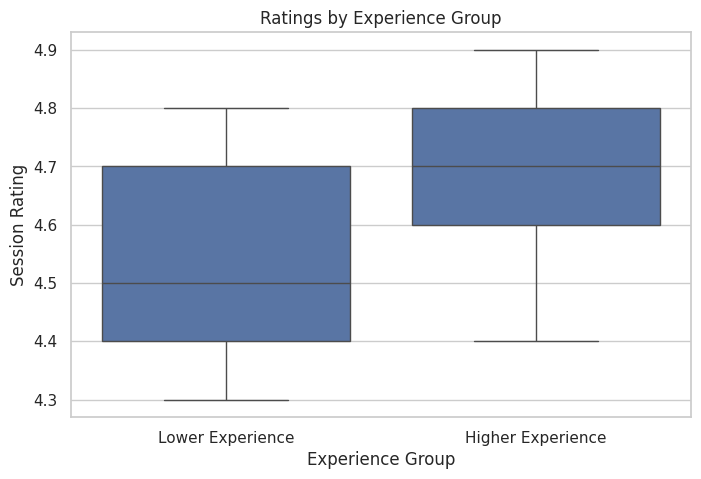

In [17]:

df["experience_group"] = np.where(
    df["experience_years"] < median_experience,
    "Lower Experience",
    "Higher Experience"
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="experience_group",
    y="session_rating"
)

plt.title("Ratings by Experience Group")
plt.xlabel("Experience Group")
plt.ylabel("Session Rating")
plt.show()


5. Unsupervised exploration
Purpose: Group mentors with similar experience, ratings, and completed-session counts to explore possible mentor segments.

In [18]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    "experience_years",
    "session_rating",
    "completed_sessions"
]

X_cluster = df[cluster_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Scaled clustering data shape:", X_scaled.shape)


Scaled clustering data shape: (30, 3)


Code cell 5.2 — Select a suitable number of clusters

In [19]:

if len(df) < 4:
    raise ValueError("At least four mentor records are needed.")

max_k = min(6, len(df) - 1)
scores = {}

for k in range(2, max_k + 1):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    if len(set(labels)) > 1:
        scores[k] = silhouette_score(X_scaled, labels)

print("Silhouette scores:")
display(pd.DataFrame(
    scores.items(),
    columns=["Number of Clusters", "Silhouette Score"]
))

best_k = max(scores, key=scores.get)
print("Selected cluster count:", best_k)


Silhouette scores:


,Number of Clusters,Silhouette Score
0,2,0.452988
1,3,0.406146
2,4,0.373386
3,5,0.355966
4,6,0.332217


Selected cluster count: 2


6. Interactive online submission demo
Purpose: Let a candidate enter their career goal, skills, experience level, and industry to receive personalized mentor recommendations.

Code cell 5.3 — Fit K-means and visualize clusters

In [20]:

import ipywidgets as widgets
from IPython.display import display, clear_output

career_goals = sorted(
    df["primary_career_goal"].dropna().unique().tolist()
)

industries = ["Any"] + sorted(
    df["industry"].dropna().unique().tolist()
)

career_widget = widgets.Dropdown(
    options=career_goals,
    description="Career Goal:"
)

skills_widget = widgets.Text(
    value="Python; SQL",
    description="Skills:",
    placeholder="Python; Machine Learning"
)

level_widget = widgets.Dropdown(
    options=["Beginner", "Intermediate", "Advanced"],
    value="Beginner",
    description="Level:"
)

industry_widget = widgets.Dropdown(
    options=industries,
    description="Industry:"
)

top_n_widget = widgets.IntSlider(
    value=5,
    min=1,
    max=min(10, len(df)),
    description="Top N:"
)

submit_button = widgets.Button(
    description="Find Mentors",
    button_style="success"
)

output = widgets.Output()

def submit_candidate(_):
    with output:
        clear_output(wait=True)

        try:
            selected_industry = (
                "" if industry_widget.value == "Any"
                else industry_widget.value
            )

            result = recommend_mentors(
                career_goal=career_widget.value,
                skills=skills_widget.value,
                level=level_widget.value,
                industry=selected_industry,
                top_n=top_n_widget.value
            )

            print("Recommended mentors:")
            display(result)

        except Exception as error:
            print("Unable to generate recommendations:", error)

submit_button.on_click(submit_candidate)

display(
    widgets.VBox([
        career_widget,
        skills_widget,
        level_widget,
        industry_widget,
        top_n_widget,
        submit_button,
        output
    ])
)
